## 15.Memory/Conversation History

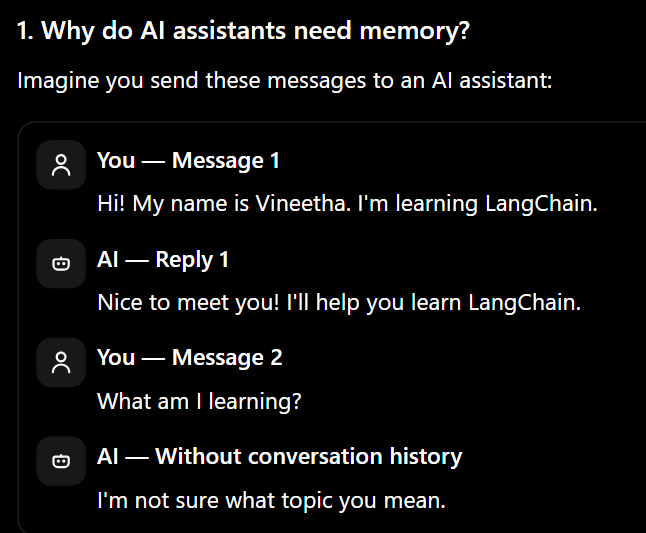

In [62]:
from langchain_groq import ChatGroq

model=ChatGroq(model_name="openai/gpt-oss-20b")

### See why memory is needed

In [24]:
res=model.invoke("My favourite programming language is Java.")
print(res.content)

That’s great! Java is a classic choice—its portability, robust ecosystem, and strong community support make it a solid foundation for many projects. What do you enjoy most about Java? Are you working on any particular type of application right now?


In [25]:
res2=model.invoke("What is my favourite language?")
print(res2.content)

I’m not sure—what’s your favourite language?


The second answer might not know your preference because we didn't provide the first interaction.

In [26]:
# create conversational history
from langchain_core.messages import HumanMessage,AIMessage

history=[
    HumanMessage(content="My name is Vineetha."),
    AIMessage(content="Hi Vineetha!"),
    HumanMessage(content="I am Learning LangChain."),
    AIMessage(content="Great! Let's learn it step by step.")
]

In [27]:
# Ask a follow up question

messages=history + [HumanMessage(content="What i am learning?")]
response=model.invoke(messages)
print(response.content)

You’re diving into **LangChain** – a toolkit that lets you build applications on top of large language models (LLMs) with a few “chain”‑like building blocks.  
Here’s a quick snapshot of what you’re learning and why it matters:

| What you’re learning | Why it matters |
|----------------------|----------------|
| **LLM fundamentals** – how GPT‑4, Claude, etc. understand text | Sets the foundation for everything that follows |
| **Prompt engineering** – crafting the right prompt, temperature, stop‑words | Directly controls the model’s output quality |
| **Chains & LLM Chains** – chaining prompts, post‑processing, and callbacks | Turns a single LLM call into a reusable workflow |
| **Memory & State** – ConversationMemory, VectorStoreMemory, etc. | Enables context‑aware, multi‑turn interactions |
| **Agents** – AutoGPT, ReAct, etc. | Lets the model decide which tools or steps to take |
| **Tool integration** – APIs, databases, web scraping, etc. | Makes your LLM do real work (e.g., fetch 

In [28]:
# Let's create a basic chatbot loop using your existing llm

hist=[]
def chat(user_input):
    hist.append(HumanMessage(content=user_input))
    res=model.invoke(hist)
    hist.append(AIMessage(content=res.content))
    return res.content

In [29]:
print(chat("My favourite programming language is Java"))
print(chat("What is my favourite programming language?"))

That’s great! Java has a lot to offer—whether you’re building enterprise applications, Android apps, or even high‑performance back‑ends. What do you enjoy most about Java? Is it the robust type system, the vast ecosystem of libraries, its portability, or something else? If you’re looking for tips, new features, or just want to share your favorite projects, I’m all ears!
Your favourite programming language is **Java**.


In [30]:
hist

[HumanMessage(content='My favourite programming language is Java', additional_kwargs={}, response_metadata={}),
 AIMessage(content='That’s great! Java has a lot to offer—whether you’re building enterprise applications, Android apps, or even high‑performance back‑ends. What do you enjoy most about Java? Is it the robust type system, the vast ecosystem of libraries, its portability, or something else? If you’re looking for tips, new features, or just want to share your favorite projects, I’m all ears!', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='What is my favourite programming language?', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Your favourite programming language is **Java**.', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]


### Our practical learning plan
<pre>
1. First: Store and retrieve messages using SQLite and Python.
2. Next: Connect stored messages to LangChain using `SQLChatMessageHistory`.
3. Then: Add a session ID so different users or conversations don't mix their histories.
4. Finally: Learn short-term memory, long-term memory, summarization, and context-window management.
5. bro let us do this step by step
</pre>

## Using SQLite & Python

In [31]:
import sqlite3

# Check the version of SQLite installed
print(f"SQLite is installed! Version: {sqlite3.sqlite_version}")

SQLite is installed! Version: 3.50.4


In [32]:
# Create database 
import sqlite3

conn=sqlite3.connect('chat_his.db')
cursor=conn.cursor()

In [33]:
# Create table
cursor.execute("""
 CREATE TABLE IF NOT EXISTS messages(
   id INTEGER PRIMARY KEY AUTOINCREMENT,
   session_id TEXT NOT NULL,
   role TEXT NOT NULL,
   content TEXT NOT NULL
  )
""")
conn.commit()
print("Database and table created successfully!")

Database and table created successfully!


In [34]:
# Insert a user message into db
cursor.execute(
  """
  INSERT INTO messages(session_id,role,content) 
  VALUES (?,?,?)
  """,
  ("chat_001","user","My name is Vineetha, and I am learning LangChain.")
)

conn.commit()

In [35]:
# Retrieve the stored message

cursor.execute(
    "SELECT id,session_id,role,content FROM messages"
)
messages=cursor.fetchall()

for msg in messages:
    print(msg)

(1, 'chat_001', 'user', 'My name is Vineetha, and I am learning LangChain.')


In [36]:

cursor.execute(
    """
    INSERT INTO messages (session_id, role, content)
    VALUES (?, ?, ?)
    """,
    (
        "chat_001",
        "assistant",
        "LangChain helps us build applications powered by large language models."
    )
)

conn.commit()

print("Assistant message stored!")

Assistant message stored!


In [37]:
# retrieve
cursor.execute(
    """
    SELECT role, content
    FROM messages
    WHERE session_id = ?
    ORDER BY id
    """,
    ("chat_001",)
)

messages = cursor.fetchall()

for role, content in messages:
    print(f"{role}: {content}")

user: My name is Vineetha, and I am learning LangChain.
assistant: LangChain helps us build applications powered by large language models.


In [38]:
# function to store any message

def save_message(session_id, role, content):
    cursor.execute(
        """
        INSERT INTO messages (session_id, role, content)
        VALUES (?, ?, ?)
        """,
        (session_id, role, content)
    )
    conn.commit()

    print(f"{role} message saved!")

In [39]:

save_message(
    "chat_001",
    "user",
    "What is an LLM?"
)

user message saved!


In [40]:
save_message(
    "chat_001",
    "assistant",
    "An LLM is a large language model."
)

assistant message saved!


In [41]:
# Create a function to retrieve a conversation
def get_messages(session_id):
    cursor.execute(
        """
        SELECT role, content
        FROM messages
        WHERE session_id = ?
        ORDER BY id
        """,
        (session_id,)
    )

    return cursor.fetchall()

In [42]:
conversation = get_messages("chat_001")

for role, content in conversation:
    print(f"{role}: {content}")

user: My name is Vineetha, and I am learning LangChain.
assistant: LangChain helps us build applications powered by large language models.
user: What is an LLM?
assistant: An LLM is a large language model.


In [43]:

# Create two separate conversations
save_message("chat_002", "user", "I am learning Python.")
save_message("chat_002", "assistant", "Python is a programming language.")

save_message("chat_003", "user", "I am learning Java.")
save_message("chat_003", "assistant", "Java is an object-oriented language.")

user message saved!
assistant message saved!
user message saved!
assistant message saved!


In [44]:

for role, content in get_messages("chat_002"):
    print(f"{role}: {content}")

user: I am learning Python.
assistant: Python is a programming language.


In [45]:
cursor.execute(
    "SELECT id,session_id,role,content FROM messages"
)
messages=cursor.fetchall()

for msg in messages:
    print(msg)

(1, 'chat_001', 'user', 'My name is Vineetha, and I am learning LangChain.')
(2, 'chat_001', 'assistant', 'LangChain helps us build applications powered by large language models.')
(3, 'chat_001', 'user', 'What is an LLM?')
(4, 'chat_001', 'assistant', 'An LLM is a large language model.')
(5, 'chat_002', 'user', 'I am learning Python.')
(6, 'chat_002', 'assistant', 'Python is a programming language.')
(7, 'chat_003', 'user', 'I am learning Java.')
(8, 'chat_003', 'assistant', 'Java is an object-oriented language.')


<pre>
What we did above:

"How can I store conversations?"

Python → SQLite
</pre>

## Using LangChain

<pre>
What we're doing NOW

LangChain + SQLChatMessageHistory

"How can LangChain manage those stored messages?"

LangChain → SQLChatMessageHistory → SQLite

SQLChatMessageHistory is a LangChain class that manages chat messages in an SQL database for you.
</pre>

In [57]:
from langchain_community.chat_message_histories import SQLChatMessageHistory

# Create a LangChain history object
history=SQLChatMessageHistory(session_id="chat_004",connection="sqlite:///chat_his.db")


<pre>
session_id="chat_004"

means:

"Work with the messages belonging to conversation chat_004."

connection="sqlite:///chat_his.db"

This tells LangChain:

Where should the conversation history be stored?
</pre>

In [58]:
# Add a HumanMessage
from langchain_core.messages import HumanMessage

history.add_message(
    HumanMessage(content="My name is Vineetha and I am learning Langchain from the last 2 weeks.")
)

In [59]:
# Add an AIMessage
from langchain_core.messages import AIMessage

history.add_message(
    AIMessage(content="Nice to meet you,Vineetha! and glad to hear that you are learning LangChain.")
)

In [60]:
# Retrieve the messages

history.messages

[HumanMessage(content='My name is Vineetha and I am learning Langchain.', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Nice to meet you,Vineetha!', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='My name is Vineetha and I am learning Langchain from the last 2 weeks.', additional_kwargs={}, response_metadata={}),
 AIMessage(content='Nice to meet you,Vineetha! and glad to hear that you are learning LangChain.', additional_kwargs={}, response_metadata={}, tool_calls=[], invalid_tool_calls=[])]

<pre>
Now you're telling LangChain:

SQLChatMessageHistory(
    session_id="chat_004",
    connection="sqlite:///chat_his.db"
)

"Create a history manager for chat_004 using this SQLite database."

</pre>

<pre>
Now we want to give the retrieved history to LLM 
</pre>

In [65]:
# let us create a simple chat function
from langchain_core.messages import HumanMessage

def chat(user_input):

    # 1. Get previous conversation
    messages = history.messages

    # 2. Add the new user question
    messages.append(
        HumanMessage(content=user_input)
    )

    # 3. Send conversation to the LLM
    response = model.invoke(messages)

    # 4. Save the user message
    history.add_message(
        HumanMessage(content=user_input)
    )

    # 5. Save the AI response
    history.add_message(response)

    # 6. Return the response
    return response.content

In [66]:
print(chat("What am I learning?"))

You’re learning **LangChain** – a Python framework that makes it easier to build applications powered by large language models (LLMs). In the past two weeks you’ve been exploring how LangChain lets you:

1. **Connect to LLMs** (OpenAI, Anthropic, Cohere, etc.) and send prompts.  
2. **Chain together multiple LLM calls** (prompt → LLM → post‑processing → LLM → …).  
3. **Use memory** (short‑term & long‑term) to keep context across turns.  
4. **Integrate external tools** (APIs, databases, web‑scraping, etc.) via the Tool interface.  
5. **Build agents** that decide which tool to call and when.  
6. **Create reusable components** (chains, prompts, callbacks) to compose complex workflows.  

You’re likely working through tutorials, experimenting with sample notebooks, and maybe building a simple chatbot or data‑analysis tool to see how the pieces fit together. If you have specific questions about any part of LangChain, feel free to ask!


In [67]:
for message in history.messages:
    print(
        type(message).__name__,
        ":",
        message.content
    )

HumanMessage : My name is Vineetha and I am learning Langchain.
AIMessage : Nice to meet you,Vineetha!
HumanMessage : My name is Vineetha and I am learning Langchain from the last 2 weeks.
AIMessage : Nice to meet you,Vineetha! and glad to hear that you are learning LangChain.
HumanMessage : What am I learning?
AIMessage : You’re learning **LangChain** – a Python framework that makes it easier to build applications powered by large language models (LLMs). In the past two weeks you’ve been exploring how LangChain lets you:

1. **Connect to LLMs** (OpenAI, Anthropic, Cohere, etc.) and send prompts.  
2. **Chain together multiple LLM calls** (prompt → LLM → post‑processing → LLM → …).  
3. **Use memory** (short‑term & long‑term) to keep context across turns.  
4. **Integrate external tools** (APIs, databases, web‑scraping, etc.) via the Tool interface.  
5. **Build agents** that decide which tool to call and when.  
6. **Create reusable components** (chains, prompts, callbacks) to compose